In [1]:
import pandas as pd

df = pd.read_csv("bike.csv", encoding="cp932")

In [2]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bike.csv"
encoding = "cp932"

# 千葉県警のCSVはShift-JIS（CP932）。追加インストールは不要
import csv
with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

10054

日本語フォントに対応させる。このコードは過去に使用済み。これだけでは動かなかったので下に追加。

In [3]:
%pip install matplotlib-fontja
import matplotlib_fontja

Note: you may need to restart the kernel to use updated packages.


In [4]:
print("施錠した:", (df["施錠関係"] == "施錠した").sum(), "件")
print("施錠せず:", (df["施錠関係"] == "施錠せず").sum(), "件")

施錠した: 3175 件
施錠せず: 6879 件


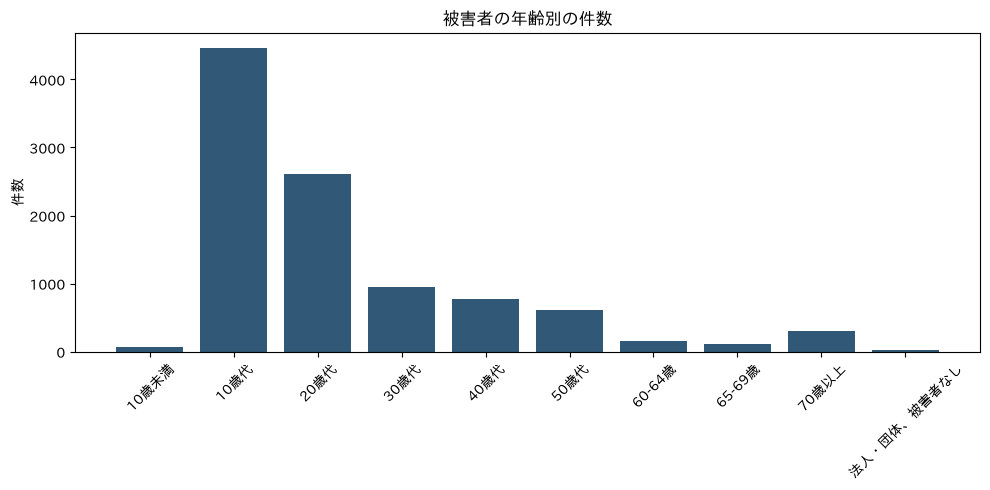

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("bike.csv", encoding="cp932")

ages = [
    "10歳未満", "10歳代", "20歳代", "30歳代", "40歳代",
    "50歳代", "60-64歳", "65-69歳", "70歳以上",
    "法人・団体、被害者なし"
]

age_counts = df["被害者の年齢"].value_counts().reindex(ages, fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(age_counts.index, age_counts.values, color="#315876")
plt.ylabel("件数")
plt.title("被害者の年齢別の件数")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 「鍵をせず」がよく盗まれている。そして１０代の被害が多い。みんなも気を付けよう！！！！！終わり。

というわけにもいかないので...


















# 実際にデータを自分で作ってみて実感して防犯意識を高めよう！！

# 

抽出回数: 25
施錠状況: 施錠せず
被害者の年齢: 10歳代


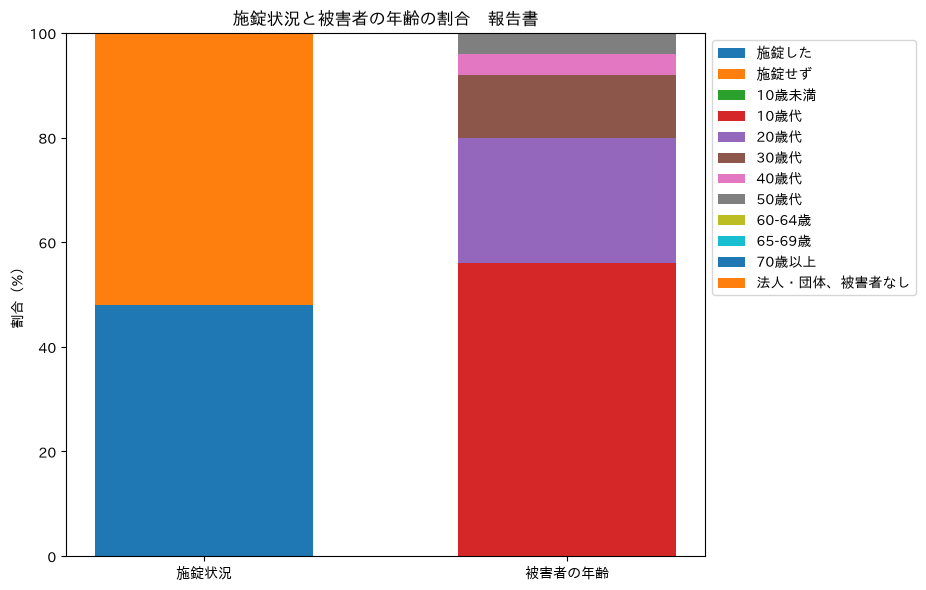

ーーーーー終了ーーーーー


In [6]:
import random#week05からそのまま
import pandas as pd
import matplotlib.pyplot as plt # グラフ作成に使うweek06『問いに合う、グラフを選ぼう。』から
from IPython.display import clear_output

df = pd.read_csv("bike.csv", encoding="cp932")

locks = ["施錠した", "施錠せず"]

ages = [
    "10歳未満",
    "10歳代",
    "20歳代",
    "30歳代",
    "40歳代",
    "50歳代",
    "60-64歳",
    "65-69歳",
    "70歳以上",
    "法人・団体、被害者なし"
]

# 抽出回数と各区分の回数
lock_counts = {lock: 0 for lock in locks}
age_counts = {age: 0 for age in ages}
count = 0

while True:#whileで繰り返し

    random_index = random.randint(0, len(df) - 1)
    bike = df.iloc[random_index]

    # 抽出回数を増やす
    count += 1

    lock = bike["施錠関係"]
    age = bike["被害者の年齢"]

    # 各区分の抽出回数を増やす
    lock_counts[lock] += 1
    age_counts[age] += 1

    # 前回の表示を消す
    clear_output(wait=True)

    print("抽出回数:", count)
    print("施錠状況:", lock)
    print("被害者の年齢:", age)

    locked = lock_counts["施錠した"] / count * 100
    unlocked = lock_counts["施錠せず"] / count * 100
#1つずつデータが増える仕組みというのは理解していた。AIにより年齢区分ごとの割合を計算が必要だった。age_base で積み上げ計算させる必要があった。
    age_0 = age_counts[ages[0]] / count * 100
    age_1 = age_counts[ages[1]] / count * 100
    age_2 = age_counts[ages[2]] / count * 100
    age_3 = age_counts[ages[3]] / count * 100
    age_4 = age_counts[ages[4]] / count * 100
    age_5 = age_counts[ages[5]] / count * 100
    age_6 = age_counts[ages[6]] / count * 100
    age_7 = age_counts[ages[7]] / count * 100
    age_8 = age_counts[ages[8]] / count * 100
    age_9 = age_counts[ages[9]] / count * 100

    # 100%積み上げ棒グラフを作成　問いに合うグラフを選ぼうから
    plt.figure(figsize=(12, 6))

    # 1本目施錠状況
    plt.bar(0, locked, label="施錠した", width=0.6)
    plt.bar(0, unlocked, bottom=locked, label="施錠せず", width=0.6)

    # 2本目被害者の年齢
    plt.bar(1, age_0, label=ages[0], width=0.6)

    age_base = age_0
    plt.bar(1, age_1, bottom=age_base, label=ages[1], width=0.6)
    age_base += age_1

    plt.bar(1, age_2, bottom=age_base, label=ages[2], width=0.6)
    age_base += age_2

    plt.bar(1, age_3, bottom=age_base, label=ages[3], width=0.6)
    age_base += age_3

    plt.bar(1, age_4, bottom=age_base, label=ages[4], width=0.6)
    age_base += age_4

    plt.bar(1, age_5, bottom=age_base, label=ages[5], width=0.6)
    age_base += age_5

    plt.bar(1, age_6, bottom=age_base, label=ages[6], width=0.6)
    age_base += age_6

    plt.bar(1, age_7, bottom=age_base, label=ages[7], width=0.6)
    age_base += age_7

    plt.bar(1, age_8, bottom=age_base, label=ages[8], width=0.6)
    age_base += age_8

    plt.bar(1, age_9, bottom=age_base, label=ages[9], width=0.6)

    plt.ylim(0, 100)
    plt.ylabel("割合（%）")
    plt.xticks([0, 1], ["施錠状況", "被害者の年齢"])
    plt.title("施錠状況と被害者の年齢の割合　報告書")
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.tight_layout(rect=[0, 0, 0.78, 1])
    plt.show()

# yまたはyes以外が入力されたら繰り返しを終了するweek05
    answer = input("次の事件に移りますか？ ")

    if answer.strip() !="":
        break

print("ーーーーー終了ーーーーー")


ブラウザ上で現在のプログラムを動かすには、Pythonとは異なるJavaScriptなどの言語を用いて、処理を書き換える必要があることが分かった。今回はJavaScriptによる実装に必要な知識・技術が不足しているため、ブラウザ上での動作は実現できなかった。